# 5. Topic clusters with K-means and Model C (WELFake)

Published classifiers reach 96–99% accuracy on WELFake. Part of the project asks **how much of that comes from
shortcuts** instead of an understanding of fake news. Notebook 04 handled one shortcut, near-duplicate copies of the same
story. This notebook handles another: **topic overlap**. The four source datasets cover different subjects in different
proportions, so a model may learn "this topic is usually fake" instead of how fake news is written.

K-means groups the articles into topics without ever seeing a label. We use the clusters in two ways:

1. **To measure the topic shortcut.** How well can the label be predicted from the cluster alone?
2. **Model C.** One logistic regression per cluster, so each classifier specialises in one topic. Does that beat a single
   global classifier on the same features?

The code is in `fake_news.models.model_c`; `scripts/run_model_c.py` tunes and saves Model C (predictions for Model D,
tables in `reports/model_c/`). Everything is fitted on **train** only and scored on **val**; test is not used here.
Main split: `grouped` (near-duplicate groups kept together), the final split of the project.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import davies_bouldin_score, roc_auc_score, silhouette_score

from fake_news import config
from fake_news.data import load_dataset
from fake_news.evaluation import evaluate
from fake_news.models import model_c as mc
from fake_news.similarity.plots import BARS, FAKE, INK2, MUTED, REAL, save, use_style

use_style()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
REPORTS = config.PROJECT_ROOT / "reports" / "model_c"

df = load_dataset("grouped", columns=["content"])
train, val = (df[df.split == s].reset_index(drop=True) for s in ("train", "val"))
ytr, yva = train.is_fake.to_numpy(), val.is_fake.to_numpy()
print(f"train {len(train):,} ({ytr.mean():.1%} fake)   val {len(val):,} ({yva.mean():.1%} fake)")

train 43,765 (44.4% fake)   val 9,380 (44.4% fake)


## 1. Features: TF-IDF and SVD

K-means needs every article as a vector of numbers. Two steps, both fitted on train only:

- **TF-IDF.** One column per word (vocabulary of up to 50,000 words that appear in at least 5 training articles and in at
  most half of them; English stop words removed). A word's weight grows with how often it appears in the article
  (sub-linear: $1 + \log tf$) and with how rare it is across articles (IDF). The matrix is *sparse*: an article uses only
  a few hundred of the words.
- **SVD (LSA).** `TruncatedSVD` compresses the TF-IDF matrix to 200 dense dimensions. Each dimension is a pattern of
  words that tend to appear together, so two articles about the same topic end up close even if one says "vote" and
  the other "ballot". The vectors are then L2-normalised: on unit vectors, Euclidean K-means groups by cosine similarity.

K-means runs on the 200 SVD dimensions. The classifiers later use the full TF-IDF words, because single words carry the
fake/real signal and SVD would blur them.

In [2]:
t0 = time.perf_counter()
feats = mc.TopicFeatures()
Xtr, Ztr = feats.fit_transform(train.content)
Xva, Zva = feats.transform(val.content)
print(f"TF-IDF: {Xtr.shape[0]:,} x {Xtr.shape[1]:,}, {Xtr.nnz / Xtr.shape[0]:.0f} non-zero words per article "
      f"({100 * Xtr.nnz / np.prod(Xtr.shape):.2f}% of the matrix)")
print(f"SVD: {feats.n_components} dimensions keep {feats.explained_variance:.1%} of the variance "
      f"({time.perf_counter() - t0:.0f} s for both steps)")

terms = feats.tfidf.get_feature_names_out()
pd.DataFrame([{"dimension": i,
               "+ words": ", ".join(terms[np.argsort(-feats.svd.components_[i])[:7]]),
               "- words": ", ".join(terms[np.argsort(feats.svd.components_[i])[:7]])} for i in range(1, 7)]
             ).set_index("dimension")

TF-IDF: 43,765 x 48,130, 189 non-zero words per article (0.39% of the matrix)
SVD: 200 dimensions keep 15.4% of the variance (10 s for both steps)


,+ words,- words
dimension,,
1,"clinton, trump, hillary, republican, donald, campaign, candidate","minister, military, korea, syria, united, government, iran"
2,"trump, house, senate, republican, russia, committee, russian","police, people, like, man, just, black, life"
3,"russia, russian, clinton, fbi, hillary, trump, comey","tax, obamacare, republicans, senate, percent, legislation, health"
4,"trump, korea, north, donald, nuclear, china, missile","fbi, investigation, federal, comey, department, court, law"
5,"clinton, party, voters, election, hillary, vote, democratic","korea, trump, house, north, white, nuclear, china"
6,"clinton, hillary, korea, china, eu, percent, emails","trump, house, senate, islamic, syria, republican, white"


Each SVD dimension is a contrast between two themes: dimension 1 separates the US election from international affairs,
dimension 3 the Russia/FBI investigation from legislation, dimension 4 North Korea from courts and investigations.
SVD found these topics without any label.

**Only ~15% of the variance is kept.** That is expected for text: most of the variance is words specific to a single
article (names, places, rare expressions) that no shared topic explains. What clustering needs is the shared topic
structure, which the first dimensions carry. The curve below shows how the variance accumulates.

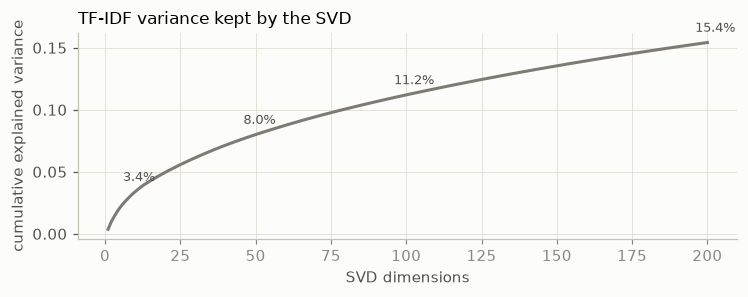

In [3]:
ev = np.cumsum(feats.svd.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(np.arange(1, len(ev) + 1), ev, color=BARS, linewidth=2)
for d in (10, 50, 100, 200):
    ax.annotate(f"{ev[d - 1]:.1%}", (d, ev[d - 1]), textcoords="offset points", xytext=(-8, 7), fontsize=8.5, color=INK2)
ax.set_xlabel("SVD dimensions"); ax.set_ylabel("cumulative explained variance")
ax.set_title("TF-IDF variance kept by the SVD")
save(fig, "kmeans_svd_variance"); plt.show()

## 2. K-means and the choice of K

**Lloyd's algorithm** (week 6): choose K centroids, assign every article to its nearest centroid, move every centroid to
the mean of its articles, repeat until no article changes cluster. The result depends on the start, so we use
**k-means++** initialisation (each new starting centroid far from the previous ones) and keep the best of 10 runs
(`n_init=10`). K-means minimises the **inertia**, the total squared distance of the articles to their centroids.

There is no "correct" K for news topics, so we look at several criteria for K = 2 … 64:

- **Inertia** always decreases with K. An *elbow*, where it stops dropping quickly, suggests a natural K.
- **Davies–Bouldin index** (week 6): for each cluster, the worst ratio (spread of the two clusters) / (distance between
  their centroids), averaged. Lower = tighter, better separated clusters.
- **Silhouette** (on 5,000 sampled training articles): $(b - a) / \max(a, b)$ with $a$ the mean distance to the own
  cluster and $b$ to the nearest other cluster. Near 1 = clearly placed, near 0 = on a border.

For Model C the deciding criterion is downstream: the val ROC-AUC of the classifier (section 5). These metrics describe
the clusters and support that choice.

In [4]:
K_LIST = [2, 4, 8, 16, 32, 64]
sample = np.random.default_rng(config.SEED).choice(len(Ztr), 5000, replace=False)
kms, rows = {}, []
for k in K_LIST:
    t0 = time.perf_counter()
    kms[k] = km = mc.fit_kmeans(Ztr, k)
    sizes = np.bincount(km.labels_, minlength=k)
    share = np.array([ytr[km.labels_ == j].mean() for j in range(k)])
    rows.append({"K": k, "inertia": km.inertia_, "davies_bouldin": davies_bouldin_score(Ztr, km.labels_),
                 "silhouette": silhouette_score(Ztr[sample], km.labels_[sample]),
                 "largest cluster": sizes.max() / len(Ztr), "smallest cluster (articles)": sizes.min(),
                 "fake share range": f"{share.min():.0%} - {share.max():.0%}",
                 "topic-only val AUC": roc_auc_score(yva, mc.topic_only_proba(share, km.predict(Zva), ytr.mean())),
                 "seconds": time.perf_counter() - t0})
kmetrics = pd.DataFrame(rows).set_index("K")
kmetrics.style.format({"inertia": "{:,.0f}", "davies_bouldin": "{:.2f}", "silhouette": "{:.3f}",
                       "largest cluster": "{:.1%}", "topic-only val AUC": "{:.3f}", "seconds": "{:.1f}"})

,inertia,davies_bouldin,silhouette,largest cluster,smallest cluster (articles),fake share range,topic-only val AUC,seconds
K,,,,,,,,
2,"35,448",5.71,0.027,53.8%,20205,24% - 68%,0.722,0.6
4,"34,255",5.21,0.024,27.8%,9831,20% - 72%,0.748,1.0
8,"32,788",4.57,0.029,18.8%,2889,18% - 84%,0.762,1.3
16,"30,930",4.21,0.039,12.6%,973,7% - 85%,0.768,2.0
32,"28,716",3.49,0.050,8.8%,253,0% - 87%,0.807,3.4
64,"25,736",3.03,0.075,5.2%,102,0% - 100%,0.815,4.9


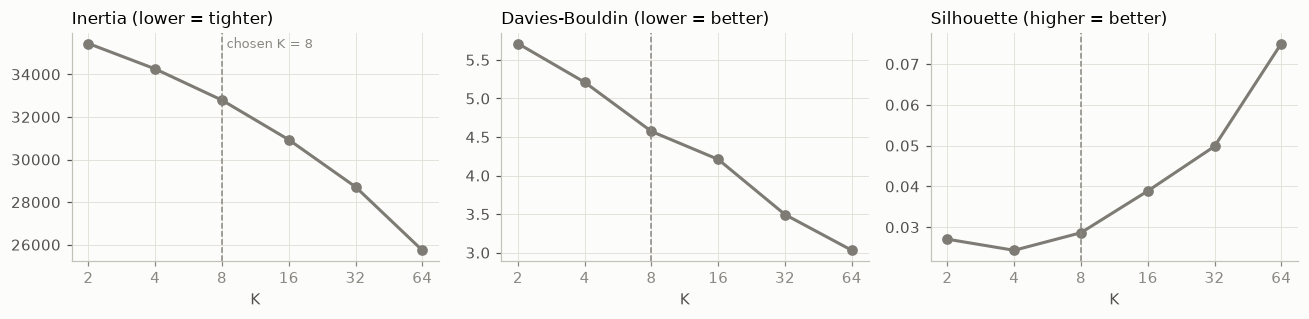

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, title in zip(axes, ["inertia", "davies_bouldin", "silhouette"],
                          ["Inertia (lower = tighter)", "Davies-Bouldin (lower = better)", "Silhouette (higher = better)"]):
    ax.plot(kmetrics.index, kmetrics[col], "o-", color=BARS, linewidth=2)
    ax.axvline(8, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xscale("log", base=2); ax.set_xticks(K_LIST, [str(k) for k in K_LIST]); ax.set_xlabel("K")
    ax.set_title(title)
axes[0].text(8.4, axes[0].get_ylim()[1] * 0.995, "chosen K = 8", color=MUTED, fontsize=8.5, va="top")
save(fig, "kmeans_choose_k"); plt.show()

**No clear elbow, and the silhouette stays between 0.02 and 0.08.** Inertia falls smoothly and Davies–Bouldin keeps improving
up to K = 64. This is typical for text: topics blend into each other ("Trump + Russia" next to "Russia + Putin"), so
there is no natural number of groups, and many articles sit near a border between two clusters (low silhouette). The
clusters are meaningful (section 3) but **overlapping**, a limitation of hard K-means assignments on text
(week 6: K-means assumes compact, well-separated, similarly sized clusters).

The choice of K therefore comes from Model C's val score (section 5): **K = 8**. The size imbalance is moderate there:
the largest cluster holds about 19% of the training articles and the smallest still about 2,900.

## 3. What the clusters are (K = 8)

The top words of a cluster are found by mapping its centroid back from SVD space to word space
(`svd.inverse_transform`) and taking the largest weights.

In [6]:
K = 8
km = kms[K]
lab_tr, lab_va = km.labels_, km.predict(Zva)
top = feats.top_terms(km.cluster_centers_, 10)
clusters = pd.DataFrame({"cluster": range(K),
                         "train articles": np.bincount(lab_tr, minlength=K),
                         "share of train": np.bincount(lab_tr, minlength=K) / len(lab_tr),
                         "fake share": [ytr[lab_tr == j].mean() for j in range(K)],
                         "top words": [", ".join(t) for t in top]}).sort_values("fake share", ascending=False)
clusters.style.format({"share of train": "{:.1%}", "fake share": "{:.1%}", "train articles": "{:,}"}).hide(axis="index")

cluster,train articles,share of train,fake share,top words
3,"7,817",17.9%,83.8%,"trump, donald, just, people, video, like, watch, know, don, white"
0,"3,256",7.4%,57.7%,"fbi, clinton, comey, trump, investigation, russia, hillary, emails, russian, intelligence"
5,"6,000",13.7%,50.3%,"like, people, new, just, time, world, years, mr, life, make"
4,"5,046",11.5%,48.6%,"clinton, hillary, trump, republican, election, campaign, presidential, voters, candidate, party"
2,"3,968",9.1%,45.2%,"police, officers, arrested, man, people, officer, killed, city, year, shooting"
1,"2,889",6.6%,28.5%,"syria, military, forces, syrian, islamic, al, iraq, war, state, killed"
6,"6,543",15.0%,22.4%,"trump, house, senate, republican, republicans, federal, tax, obama, congress, court"
7,"8,246",18.8%,17.6%,"minister, united, korea, government, china, trump, north, states, foreign, prime"


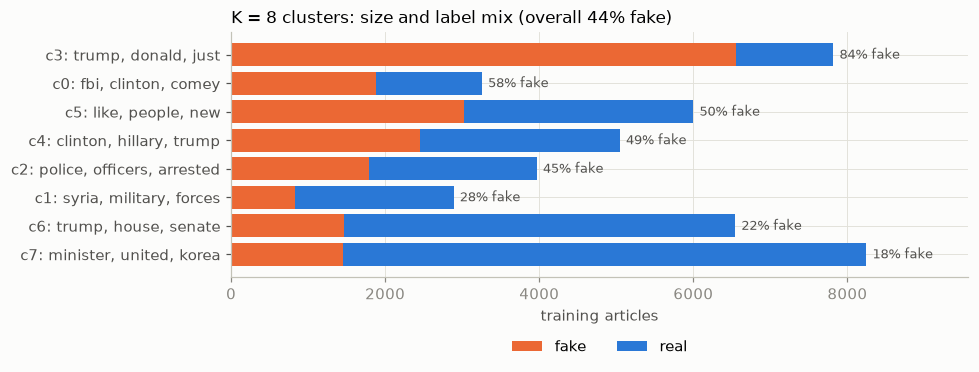

In [7]:
c = clusters.reset_index(drop=True)
names = [", ".join(t.split(", ")[:3]) for t in c["top words"]]
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(c))[::-1]
n_fake = c["train articles"] * c["fake share"]
ax.barh(y, n_fake, color=FAKE, label="fake")
ax.barh(y, c["train articles"] - n_fake, left=n_fake, color=REAL, label="real")
for yi, (n, s) in zip(y, zip(c["train articles"], c["fake share"])):
    ax.text(n + 80, yi, f"{s:.0%} fake", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"c{j}: {nm}" for j, nm in zip(c.cluster, names)])
ax.set_xlim(0, c["train articles"].max() * 1.16)
ax.set_xlabel("training articles"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title(f"K = {K} clusters: size and label mix (overall {ytr.mean():.0%} fake)")
save(fig, "kmeans_clusters_fake_share"); plt.show()

The clusters are recognisable news topics: international affairs and North Korea, Congress and legislation, the 2016
election, the FBI/Clinton-email/Russia story, Syria, crime and police, and a general "lifestyle" cluster. Their label mix
differs strongly: from about **18% fake** (international affairs) to about **84% fake**.

**The most fake cluster is a style, not a subject.** Its top words are *trump, donald, just, people, video, like,
watch, know, don*: an informal, opinionated blog tone ("watch this video, you just don't know…"). So K-means groups
partly by **writing style**, which is tied to the source. Cleaning removed explicit source markers but deliberately kept
house style such as "Watch the video below" and "Mr." (cleaning decisions G4 and G8 in `reports/cleaning/DECISIONS.md`).
The clusters show that this style still carries the label. Below we therefore speak of a **cluster shortcut**
(topic + style), not a pure topic shortcut.

## 4. The cluster shortcut: how much does the cluster alone reveal?

A reference predictor that reads nothing but the cluster: P(fake) = fake share of the article's cluster in train.
Its val ROC-AUC measures how much of the label is predictable from the topic/style group alone
(0.5 = nothing, 1 = everything).

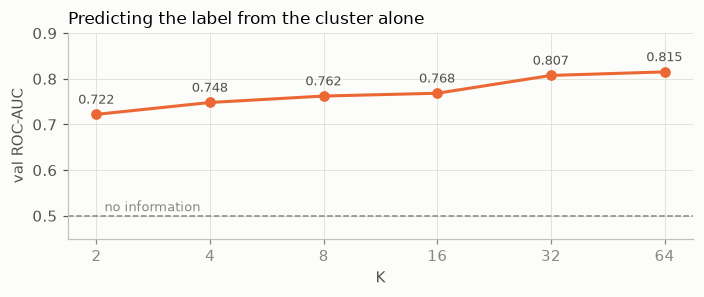

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(kmetrics.index, kmetrics["topic-only val AUC"], "o-", color=FAKE, linewidth=2)
for k, v in kmetrics["topic-only val AUC"].items():
    ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(-12, 7), fontsize=8.5, color=INK2)
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1); ax.text(2.1, 0.51, "no information", color=MUTED, fontsize=8.5)
ax.set_xscale("log", base=2); ax.set_xticks(K_LIST, [str(k) for k in K_LIST]); ax.set_ylim(0.45, 0.9)
ax.set_xlabel("K"); ax.set_ylabel("val ROC-AUC"); ax.set_title("Predicting the label from the cluster alone")
save(fig, "kmeans_topic_only_auc"); plt.show()

**The cluster alone reaches a val ROC-AUC of about 0.76 at K = 8 and 0.81 at K = 32–64.** Without reading a single
word beyond the cluster assignment, the label is ranked correctly for about four out of five fake/real pairs. With
more clusters the shortcut gets sharper: at K = 32–64 the fake share of the clusters ranges from 0% to 100%, i.e. some
small clusters are entirely fake or entirely real. For
comparison, Model B (neighbour voting, notebook 04) reaches 0.64 on the same split. This is the third shortcut of the
project, measured: on WELFake the topic and style of an article give away much of its label. A model tested on topics
it has seen in training benefits from that, which is what the (optional) `cluster` split regime would remove.

## 5. Model C against a global logistic regression

**Model C** routes each article to its nearest centroid and scores it with that cluster's own logistic regression,
trained on the cluster's training articles with the full TF-IDF features. A cluster with fewer than 200 training
articles or a single class falls back to the global classifier (never needed at K ≤ 32).

The fair comparison is the **global LR**: one logistic regression on all training articles with exactly the same
features (Model C with K = 1). `scripts/run_model_c.py` tuned K ∈ {8, 16, 32} and C ∈ {10, 30, 100} on grouped val and
kept the chosen setting fixed on the random split; the global LR is tuned over the same C values on both splits.
We read its tables here instead of refitting.

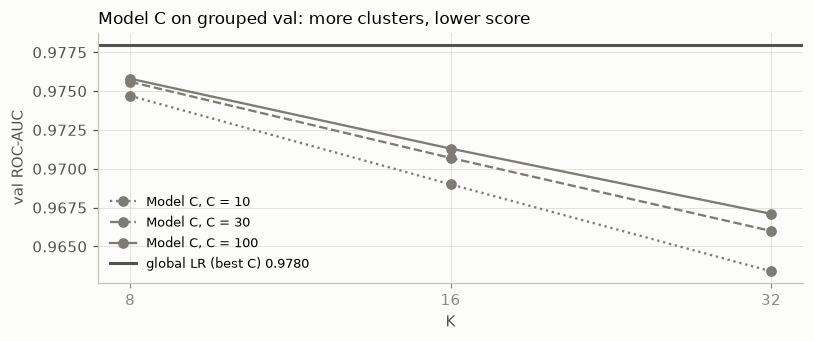

roc_auc         accuracy              f1        
split      grouped  random  grouped  random grouped  random
model                                                      
global_lr   0.9780  0.9776   0.9288  0.9281  0.9196  0.9190
model_c     0.9758  0.9759   0.9229  0.9239  0.9129  0.9147
hybrid_avg  0.9805  0.9803   0.9328  0.9325  0.9243  0.9242
topic_only  0.7623  0.7516   0.6913  0.6877  0.6312  0.5501

In [9]:
tuning = pd.read_csv(REPORTS / "grouped_tuning.csv")
summary = {r: json.loads((REPORTS / f"{r}_summary.json").read_text()) for r in ("random", "grouped")}
best_global = tuning[tuning.model == "global_lr"].roc_auc.max()

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for c_val, ls in zip((10, 30, 100), (":", "--", "-")):
    t = tuning[(tuning.model == "model_c") & (tuning.c == c_val)]
    ax.plot(t.k, t.roc_auc, ls, marker="o", color=BARS, label=f"Model C, C = {c_val:g}")
ax.axhline(best_global, color=INK2, linewidth=2,   # not REAL: blue is reserved for the "real" class
           label=f"global LR (best C) {best_global:.4f}")
ax.set_xscale("log", base=2); ax.set_xticks([8, 16, 32], ["8", "16", "32"])
ax.set_xlabel("K"); ax.set_ylabel("val ROC-AUC"); ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Model C on grouped val: more clusters, lower score")
save(fig, "model_c_vs_k"); plt.show()

rows = []
for r, s in summary.items():
    for m in ("model_c", "global_lr", "hybrid_avg", "topic_only"):
        rows.append({"split": r, "model": m, **{k: s["val"][m][k] for k in ("roc_auc", "accuracy", "f1")}})
pd.DataFrame(rows).pivot(index="model", columns="split").round(4).loc[["global_lr", "model_c", "hybrid_avg", "topic_only"]]

**Model C does not beat the global LR.** At the chosen K = 8 it is about 0.002 ROC-AUC below, and every additional
split of the data makes it worse. Each per-cluster classifier learns from fewer articles (about 5,500 instead of
43,765 at K = 8); this would pay off only if the fake/real signals differed strongly between topics. They mostly do not:
the same words and the same style give fake articles away whatever the subject. This fits section 3, where much of the
signal turned out to be writing style, which does not change with the topic.

**Random vs grouped hardly differs** for these word-based models (0.976 vs 0.976 for Model C). Near-duplicate groups
cover only 3.9% of the articles, too few to move a classifier that learns from words. Model B, which relies on finding
copies, does drop (notebook 04).

The row `hybrid_avg` (average of the global LR and Model C) is *above* both. Section 7 checks whether that gain is real.

## 6. Inside each cluster

If Model C is worse overall, is it worse in every cluster? The table compares both models on the val articles of each
cluster.

In [10]:
per = pd.read_csv(REPORTS / "grouped_clusters.csv")
per["difference"] = per.val_auc_model_c - per.val_auc_global_lr
per["top words"] = per.top_terms.str.split(", ").str[:5].str.join(", ")
per[["cluster", "n_train", "fake_share_train", "n_val", "val_auc_model_c", "val_auc_global_lr", "difference", "top words"]] \
    .style.format({"fake_share_train": "{:.1%}", "val_auc_model_c": "{:.4f}", "val_auc_global_lr": "{:.4f}",
                   "difference": "{:+.4f}", "n_train": "{:,}", "n_val": "{:,}"}).hide(axis="index")

cluster,n_train,fake_share_train,n_val,val_auc_model_c,val_auc_global_lr,difference,top words
7,"8,246",17.6%,"1,741",0.9842,0.9840,+0.0002,"minister, united, korea, government, china"
3,"7,817",83.8%,"1,619",0.9385,0.9366,+0.0019,"trump, donald, just, people, video"
6,"6,543",22.4%,"1,424",0.9590,0.9609,-0.0019,"trump, house, senate, republican, republicans"
5,"6,000",50.3%,"1,368",0.9651,0.9575,+0.0076,"like, people, new, just, time"
4,"5,046",48.6%,"1,060",0.9685,0.9730,-0.0045,"clinton, hillary, trump, republican, election"
2,"3,968",45.2%,865,0.9571,0.9625,-0.0054,"police, officers, arrested, man, people"
0,"3,256",57.7%,701,0.9689,0.9679,+0.0010,"fbi, clinton, comey, trump, investigation"
1,"2,889",28.5%,602,0.9840,0.9843,-0.0003,"syria, military, forces, syrian, islamic"


**Within each cluster the two models are almost tied** (differences below 0.01, in both directions): Model C is
slightly better in the general "lifestyle" cluster and slightly worse in the police/crime and election clusters. Yet over all
val articles Model C is lower. A likely reason: the eight classifiers are trained separately, so their probabilities
are on slightly **different scales**: a 0.8 from one cluster's model does not mean exactly what a 0.8 from another
means. ROC-AUC ranks all articles together, so mixing scales costs a little even when each model ranks well within its
own cluster. (This is an interpretation; the blend in Model D can correct scales if it also receives the cluster id.)

## 7. Does combining help, and is it the topics?

Averaging the global LR and Model C scored higher than either. But averaging *any* two models often helps a little,
so we need a **control**: what does averaging give when the second model knows nothing about topics?

- **Hybrid:** global LR (C = 10) averaged with Model C (K = 8, C = 100).
- **Control 1:** global LR (C = 10) averaged with another global LR (C = 100). Same idea, no clusters.
- **Control 2:** global LR averaged with 8 LRs trained on **random** groups of the same sizes as the clusters, each val
  article routed to a random group. Identical to the hybrid except that the groups are not topics.

The uncertainty comes from a **bootstrap**: the val set is resampled 1,000 times with replacement, and the 95% interval
of the AUC *difference* to the global LR is reported. Each resample compares all models on the same articles.

In [11]:
c_glob, c_model = summary["grouped"]["val"]["global_lr"]["c"], summary["grouped"]["c"]
g = mc.fit_global_lr(Xtr, ytr, c_glob)
p_glob = g.predict_proba(Xva)[:, 1]
p_glob2 = mc.fit_global_lr(Xtr, ytr, c_model).predict_proba(Xva)[:, 1]
p_c = mc.fit_cluster_classifiers(Xtr, ytr, lab_tr, c_model, g, k=K).predict_proba(Xva, lab_va)

rng = np.random.default_rng(config.SEED)
rand_tr = rng.permutation(lab_tr)                         # same group sizes, no topic
rand_va = rng.integers(0, K, len(yva))
p_rand = mc.fit_cluster_classifiers(Xtr, ytr, rand_tr, c_model, g, k=K).predict_proba(Xva, rand_va)

candidates = {"global LR": p_glob,
              "hybrid: global + Model C": (p_glob + p_c) / 2,
              "control 1: global + global (C=100)": (p_glob + p_glob2) / 2,
              "control 2: global + random groups": (p_glob + p_rand) / 2}
idx = rng.integers(0, len(yva), (1000, len(yva)))
base = np.array([roc_auc_score(yva[i], p_glob[i]) for i in idx])
rows = []
for name, p in candidates.items():
    diff = np.array([roc_auc_score(yva[i], p[i]) for i in idx]) - base
    rows.append({"model": name, "val ROC-AUC": roc_auc_score(yva, p),
                 "gain vs global": roc_auc_score(yva, p) - roc_auc_score(yva, p_glob),
                 "95% CI low": np.percentile(diff, 2.5), "95% CI high": np.percentile(diff, 97.5),
                 "accuracy": evaluate(yva, p)["accuracy"]})
control = pd.DataFrame(rows).set_index("model")
control.style.format("{:+.4f}", subset=["gain vs global", "95% CI low", "95% CI high"]) \
             .format("{:.4f}", subset=["val ROC-AUC", "accuracy"])

,val ROC-AUC,gain vs global,95% CI low,95% CI high,accuracy
model,,,,,
global LR,0.9780,+0.0000,+0.0000,+0.0000,0.9288
hybrid: global + Model C,0.9805,+0.0025,+0.0016,+0.0033,0.9328
control 1: global + global (C=100),0.9775,-0.0006,-0.0008,-0.0003,0.9264
control 2: global + random groups,0.9740,-0.0040,-0.0049,-0.0032,0.9177


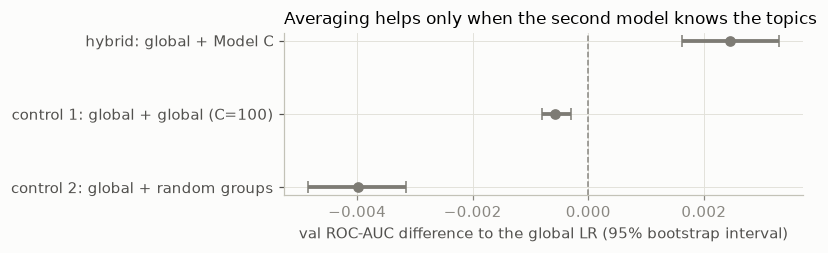

In [12]:
c2 = control.iloc[1:]
fig, ax = plt.subplots(figsize=(7.5, 2.4))
y = np.arange(len(c2))[::-1]
ax.errorbar(c2["gain vs global"], y, xerr=[c2["gain vs global"] - c2["95% CI low"], c2["95% CI high"] - c2["gain vs global"]],
            fmt="o", color=BARS, ecolor=BARS, elinewidth=2.5, capsize=4)   # neutral colour: not about fake/real
ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.xaxis.set_major_locator(plt.MaxNLocator(5))
ax.set_yticks(y, c2.index); ax.set_xlabel("val ROC-AUC difference to the global LR (95% bootstrap interval)")
ax.set_title("Averaging helps only when the second model knows the topics")
save(fig, "model_c_control"); plt.show()

- **Hybrid:** a small gain whose whole 95% interval lies above zero, so it is not luck of this val set.
- **Control 1:** averaging two global models gives no gain (even slightly less), so the gain is not the generic "two
  models are better than one".
- **Control 2:** with random groups instead of topic clusters, the same averaging **hurts**. The only difference to the
  hybrid is that Model C's groups are topics, so **the gain comes from the topics**.

*Caveat.* K and C were chosen on this same val set, so the gain may be slightly optimistic; the bootstrap interval
covers the sampling of val articles, not the randomness of training. The final test run gives the unbiased number.

**Conclusion.** Topic-specific classifiers are worse than one global classifier on their own, because each sees less
data and most of the signal is shared across topics. But they capture *something the global model misses*, and combined
with it they give a small, real improvement. This is the role Model C plays in the blend (Model D, Person 3), which
combines the val predictions of all models.

## 8. Summary and outputs

| Question | Answer (grouped val) |
|---|---|
| Are there topic clusters? | Yes, readable news topics, but overlapping (silhouette ≈ 0.03) and partly defined by writing style. |
| Is the cluster a shortcut? | Yes: the cluster alone gives ROC-AUC ≈ 0.76 (K = 8) to 0.81 (K = 32–64). |
| Do per-cluster classifiers beat one global classifier? | No: Model C 0.976 vs global LR 0.978; worse for larger K. |
| Do they add anything? | Yes, combined with the global LR: +0.002 ROC-AUC, confirmed by two controls and a bootstrap interval. |
| Do near-duplicates matter for these models? | Hardly: random and grouped give the same scores (3.9% of articles are in groups). |

**Limitations.** Hard assignments on overlapping clusters (low silhouette); K-means prefers similarly sized, round
clusters; results depend on the seed (fixed, `config.SEED`); clusters mix topic and source style, so the "topic"
shortcut also contains a source component; the per-cluster probabilities are not calibrated against each other.

| Output | Contents |
|---|---|
| `data/processed/predictions/model_c__<regime>.csv` | `doc_id, split, prob_fake` (val + test) for Model D |
| `data/processed/predictions/model_c__<regime>__clusters.csv` | cluster of every article |
| `reports/model_c/<regime>_{tuning,clusters,summary}` | tuning grid, per-cluster table, chosen setting |
| `reports/figures/kmeans_*.png`, `model_c_*.png` | figures of this notebook |

```bash
python scripts/run_model_c.py --regime grouped   # ~30 s: tunes K and C, writes predictions and reports
python scripts/run_model_c.py --regime random    # same K and C, other split
```